In [ ]:
# Abigail Birnbaum (abigail.birnbaum@pnnl.gov)
# Figures for paper "A basin-scale ensemble of plausible runoff across the contiguous United States for 1980-2024"

### Import Packages

In [ ]:
import os
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import xarray as xr

import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

### Specify Global Variables

In [3]:
# coordinate system for plotting
crs_ref = 'wgs84'
crs_proj = 'epsg:5070' #NAD83 CONUS Albers equal area- US CONUS

# list of regions
reg_list = ['huc01','huc02','huc03','huc04','huc05','huc06','huc07','huc08','huc09','huc10','huc11','huc12',
            'huc13','huc14','huc15','huc16','huc17','huc18','pfaf71','pfaf72','pfaf73','pfaf75','pfaf77','pfaf78']

# list of scenarios
scen_list = ['era5d','ic0_fhist','ic1_fhist','ic2_fhist','ic3_fhist','ic4_fhist','ic5_fhist','ic6_fhist','ic7_fhist','ic8_fhist','ic9_fhist']

In [ ]:
# paths to data
pwp = '/gcfs/projects/foresight/hydrology/'
calib_dp = pwp+'abirn_vic/input_data/calib_runoff_by_huc2/calib_target_v2/' # calibration target w/ transfer function (calibration dataset)
vic_dp = pwp+'abirn_vic/final_vic_output/' #VIC output - ERA5D and ACE2
shp_path = pwp+'abirn_vic/input_data/ncar_region_shapefiles/' #shapefiles (HUC12 + MERIT)
save_fig_path = pwp+'abirn_vic/vic_output_analysis/save_figures/'

In [5]:
# specify color palette
era5d_color = '#fdb462'
ace2_color = '#66c2a5'

era5d_color2 = '#EAB375'
ace2_color2 = '#72B6A1'

### Methods

In [ ]:
def calc_kge_decomp(df):
    """Calculate KGE and component parts """
    pred = df['calib_qf']
    obs = df['vic_qf']
    r = np.corrcoef(pred, obs)[0, 1]
    alpha = np.std(pred) / np.std(obs)
    beta = np.mean(pred) / np.mean(obs)
    gamma = alpha / beta
    kge = 1 - np.sqrt((r - 1) ** 2 + (beta - 1) ** 2 + (gamma - 1) ** 2)
    return [kge,beta,alpha,r]

### Load Raw Data

In [ ]:
# # Load in calibration target data (~52 seconds to load in)
# flist = [calib_dp + item for item in os.listdir(calib_dp)]
# calib_qf_df = pd.DataFrame()
# for f in flist[:]:
#     calib_qf_reg = xr.open_dataset(f)['calib_qf_value'].to_dataframe().reset_index().rename(columns={'calib_qf_value':'calib_qf'})
#     calib_qf_df = pd.concat([calib_qf_reg,calib_qf_df])
# calib_qf_df = calib_qf_df.reset_index().drop(columns=['index'])

In [9]:
# #load in VIC runoff data (~ 10 minutes to load in)
# vic_df = pd.DataFrame()
# for reg_sel in reg_list[:]:
#     for scen_name in scen_list[:]:
#         fname = vic_dp+reg_sel+'/monthly_vic_'+reg_sel+'_'+scen_name+'.nc'
#         vic_reg = xr.open_dataset(fname)['vic_qf'].to_dataframe().reset_index()
#         vic_df = pd.concat([vic_reg,vic_df])
# vic_df = vic_df.reset_index().drop(columns=['index'])

### Combine Datasets

In [ ]:
# # merge calibration target dataset with vic_df
# monthly_df = calib_qf_df.merge(vic_df,on=['basin','time'])

# monthly_df['region_num'] = monthly_df.basin.str[:2]
# monthly_df.loc[~monthly_df.region_num.isin(['71','72','73','75','77','78']),'region2'] = 'huc'+monthly_df['basin'].str[:2]
# monthly_df.loc[monthly_df.region_num.isin(['71','72','73','75','77','78']),'region2'] = 'pfaf'+monthly_df['basin'].str[:2]

### Save Datasets

In [ ]:
# #save (16 minutes)
# save_path = '/gcfs/projects/foresight/hydrology/abirn_vic/vic_output_analysis/saved_data/'
# vic_df.to_csv(save_path+'vic_monthly_runoff.csv',index=False)
# monthly_df.filter(['region2','basin','scenario','time','calib_qf','vic_qf']).sort_values(by=['region2','basin','time']).to_csv(save_path+'calib_qf_vic_combined_monthly_runoff.csv',index=False)

### Calculate KGE

In [12]:
# #filter monthly_df to era5d scenario
# monthly_df_kge = monthly_df[monthly_df.scenario=='era5d'].reset_index()

# # split into calibration and validation
# calib_start = '1982-01-01'
# calib_end = '2001-12-31'
# valid_start = '2002-01-01'
# valid_end = '2017-12-31'
# monthly_df_calib = monthly_df_kge[(monthly_df_kge.time>=calib_start) & (monthly_df_kge.time<=calib_end)].reset_index().drop(columns=['index'])
# monthly_df_valid = monthly_df_kge[(monthly_df_kge.time>=valid_start) & (monthly_df_kge.time<=valid_end)].reset_index().drop(columns=['index'])

# #calculate kge
# kge_calib_decomp = monthly_df_calib.groupby(['basin','region2']).apply(calc_kge_decomp).reset_index()
# kge_calib_decomp = kge_calib_decomp.rename(columns={0:'kge_output'})
# kge_calib_decomp[['kge','bias','var','corr']]= kge_calib_decomp['kge_output'].tolist()

# kge_valid_decomp = monthly_df_valid.groupby(['basin','region2']).apply(calc_kge_decomp).reset_index()
# kge_valid_decomp = kge_valid_decomp.rename(columns={0:'kge_output'})
# kge_valid_decomp[['kge','bias','var','corr']]= kge_valid_decomp['kge_output'].tolist()

# kge_decomp_merge = kge_calib_decomp.merge(kge_valid_decomp,on=['basin','region2'],suffixes=['_calib','_valid'])
# kge_decomp_merge = kge_decomp_merge.filter(['basin','region2','kge_calib','kge_valid','bias_calib','bias_valid','var_calib','var_valid','corr_calib','corr_valid'])

# #save
# kge_decomp_merge.to_csv(save_path+'monthly_kge_by_basin.csv',index=False)

### Load in Processed Datasets

In [ ]:
#takes ~8 minutes to load (sometimes much longer though...up to 35 min)
save_path = '/gcfs/projects/foresight/hydrology/abirn_vic/vic_output_analysis/saved_data/'
monthly_df = pd.read_csv(save_path+'calib_qf_vic_combined_monthly_runoff.csv',dtype={'basin':'str'})
monthly_df['time'] = pd.to_datetime(monthly_df['time']) #make sure time is correct format (datetime)

In [14]:
#link pfaf basins with huc2regions
huc2_pfaf_link = pd.read_csv('extra_data/pfaf_huc2_link.csv',dtype={'pfaf_id':'str','region2':'str'})
huc2_pfaf_link['region2'] = 'pfaf'+huc2_pfaf_link['region2']

#merge pfaf links with monthly_df --> assign new column region2_wpfaf
monthly_df = monthly_df.merge(huc2_pfaf_link,left_on=['basin','region2'],right_on=['pfaf_id','region2'],how='outer')
monthly_df.loc[monthly_df.region2.str.contains('huc'),'region2_wpfaf'] = monthly_df.region2
monthly_df.loc[monthly_df.region2.str.contains('pfaf'),'region2_wpfaf'] = monthly_df.asc_huc2

In [ ]:
# # create calibration file - netCDF
# qf_calib_df = monthly_df.filter(['region2','basin','time','calib_qf']).drop_duplicates()

# huc2_pfaf_link = pd.read_csv('pfaf_huc2_link.csv',dtype={'pfaf_id':'str','region2':'str'})
# huc2_pfaf_link['region2'] = 'pfaf'+huc2_pfaf_link['region2']

# qf_calib_df = qf_calib_df.merge(huc2_pfaf_link,left_on=['basin','region2'],right_on=['pfaf_id','region2'],how='outer')
# qf_calib_df.loc[qf_calib_df.region2.str.contains('huc'),'region2_wpfaf'] = qf_calib_df.region2
# qf_calib_df.loc[qf_calib_df.region2.str.contains('pfaf'),'region2_wpfaf'] = qf_calib_df.asc_huc2

# qf_calib_df = qf_calib_df.filter(['region2','region2_wpfaf','basin','time','calib_qf'])
# qf_calib_df = qf_calib_df.rename(columns={'region2_wpfaf':'associated_region2','calib_qf':'calib_qf_value'})
# qf_calib_df.to_csv(save_path+'qf_calib.csv',index=False)

In [16]:
#load in KGE results
kge_decomp_merge = pd.read_csv(save_path+'monthly_kge_by_basin.csv',dtype={'basin':'str'})
kge_decomp_merge = kge_decomp_merge.merge(huc2_pfaf_link,left_on=['basin','region2'],right_on=['pfaf_id','region2'],how='outer')
kge_decomp_merge.loc[kge_decomp_merge.region2.str.contains('huc'),'region2_wpfaf'] = kge_decomp_merge.region2
kge_decomp_merge.loc[kge_decomp_merge.region2.str.contains('pfaf'),'region2_wpfaf'] = kge_decomp_merge.asc_huc2

In [17]:
#load in basin shapefiles
all_reg_shp = pd.DataFrame()
for reg in reg_list:
    reg_shp = gpd.read_file(shp_path+'region_'+reg+'.shp').to_crs(crs_ref)
    all_reg_shp = pd.concat([reg_shp,all_reg_shp])

all_reg_shp_proj = all_reg_shp.to_crs(crs_proj) #project to projected coordinate system
all_reg_shp_proj['basin_area'] = all_reg_shp_proj.area #calculate basin area in m2
all_reg_shp = all_reg_shp_proj.to_crs(crs_ref) #convert back to reference coordinate system
all_reg_shp = all_reg_shp.reset_index().drop(columns=['index'])

In [18]:
all_reg_shp = all_reg_shp.rename(columns={'HUCIDX':'basin'})
all_reg_shp = all_reg_shp[all_reg_shp.basin.isin(monthly_df.basin.unique())]  #filter to basins in our dataset

all_reg_shp.loc[all_reg_shp.HUC02.isin(['01','02','03','04','05','06','07','08',
                                        '09','10','11','12','13','14','15','16',
                                        '17','18']),'region2'] = 'huc'+all_reg_shp['HUC02']
all_reg_shp.loc[all_reg_shp.pfaf.isin(['71','72','73','75','77','78']),'region2'] = 'pfaf'+all_reg_shp['pfaf']
all_reg_shp['HUC_SRC'] = all_reg_shp['HUC_SRC'].replace({'MERIT_hydro':'MERIT basins','WBDHU12':'HUC-12 basins'})
all_reg_shp['region2_upper'] = all_reg_shp['region2'].str.upper()

# #merge with huc2_pfaf link
all_reg_shp = all_reg_shp.merge(huc2_pfaf_link,left_on=['basin','region2'],right_on=['pfaf_id','region2'],how='outer')
all_reg_shp.loc[all_reg_shp.region2.str.contains('huc'),'region2_wpfaf'] = all_reg_shp.region2
all_reg_shp.loc[all_reg_shp.region2.str.contains('pfaf'),'region2_wpfaf'] = all_reg_shp.asc_huc2


In [19]:
#calculate areas by huc2_wpfaf region and total area
region2_wpfaf_area = all_reg_shp.groupby(['region2_wpfaf'])['basin_area'].sum().reset_index()
total_area = all_reg_shp['basin_area'].sum()

In [20]:
#merge basins with basin_area
monthly_df = monthly_df.merge(all_reg_shp.filter(['basin','basin_area']),on=['basin'])

### Map of HUC2 regions

In [21]:
#load in huc2 shapefiles
reg_num_list = ['01','02','03','04','05','06','07','08','09','10','11','12','13','14','15','16','17','18']
huc2_boundaries = []
huc2_shp_path = '/gcfs/projects/foresight/hydrology/abirn_vic/vic_output_analysis/extra_data/huc2_region_files/'

for reg_num in reg_num_list[:]:
    huc2_boundary = gpd.read_file(huc2_shp_path+'WBD_'+reg_num+'_HU2_Shape/Shape/WBDHU2.shp')
    huc2_boundary['region2_upper'] = 'HUC'+reg_num
    huc2_boundaries.append(huc2_boundary)

huc2_boundaries = pd.concat(huc2_boundaries,ignore_index=True)


In [22]:
pfaf_bounds = all_reg_shp[all_reg_shp.HUC_SRC=='MERIT basins'].dissolve(['region2'])
pfaf_bounds['region2'] = 'PFAF'+pfaf_bounds['pfaf']

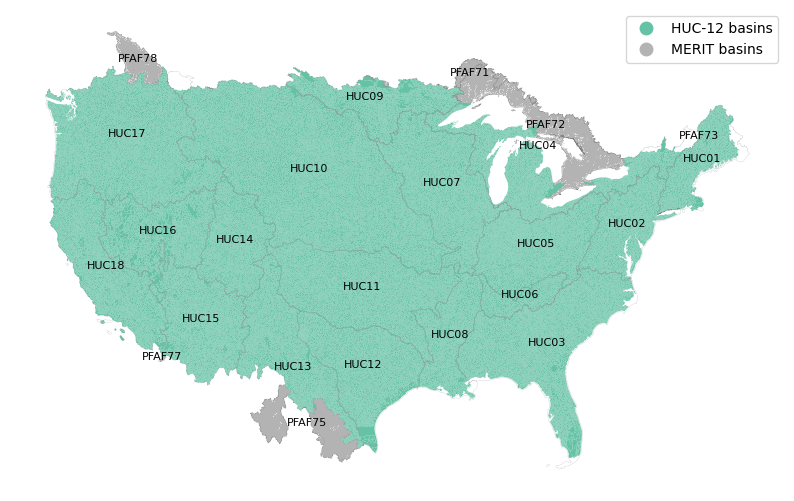

In [23]:
fig,ax = plt.subplots(1,1,figsize=(10,10))
#load in HUC-2 boundaries
all_reg_shp.plot(ax=ax,column='HUC_SRC',categorical=True,cmap='Set2',legend=True)
huc2_boundaries.boundary.plot(ax=ax,color='gray',lw=0.1)
huc2_boundaries.apply(lambda x: ax.annotate(text=x['region2_upper'], xy=x.geometry.centroid.coords[0], ha='center',fontsize=8), axis=1)
pfaf_bounds.boundary.plot(ax=ax,color='gray',lw=0.1)
pfaf_bounds.apply(lambda x: ax.annotate(text=x['region2_upper'], xy=x.geometry.centroid.coords[0], ha='center',fontsize=8), axis=1)
ax.set_axis_off();
#plt.savefig(save_fig_path+'figure1_map.pdf',bbox_inches='tight',dpi=400);
plt.savefig(save_fig_path+'figure1_map.png',bbox_inches='tight',dpi=400);

### Figure 2: KGE (model performance versus calibration dataset)

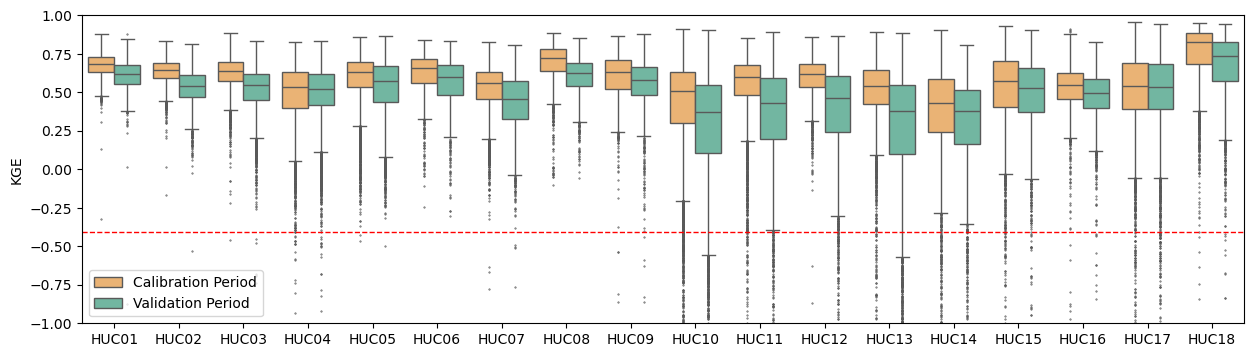

In [24]:
# boxplot 
kge_melt = kge_decomp_merge.melt(id_vars=['region2_wpfaf','basin'])
kge_melt = kge_melt[kge_melt.variable.isin(['kge_calib','kge_valid'])]
kge_melt['variable'] = kge_melt['variable'].replace({'kge_calib':'Calibration Period','kge_valid':'Validation Period'})
kge_melt['region2_wpfaf_upper'] = kge_melt['region2_wpfaf'].str.upper()

#boxplot
fig,ax = plt.subplots(1,1,figsize=(15,4))
sns.boxplot(ax=ax,data=kge_melt,x='region2_wpfaf_upper',y='value',fliersize=0.5,hue='variable',palette=[era5d_color,ace2_color],hue_order = ['Calibration Period','Validation Period'],zorder=0)
h,l = ax.get_legend_handles_labels()
ax.axhline(-0.41,color='r',ls='--',lw=1)
ax.set_ylim([-1,1]); 
ax.set_xlabel(''); ax.set_ylabel('KGE'); 
ax.legend(h,l,title='')
#plt.savefig(save_fig_path+'figure2_boxplots.pdf',bbox_inches='tight',dpi=400);
plt.savefig(save_fig_path+'figure2_boxplots.png',bbox_inches='tight',dpi=400);

In [25]:
#statistics
print('mean kge (calib): ', kge_decomp_merge.kge_calib.mean())
print('median kge (calib): ', kge_decomp_merge.kge_calib.median())
print('var kge (calib): ', kge_decomp_merge.kge_calib.var())
print('max kge (calib): ',kge_decomp_merge.kge_calib.max())
print('min kge (calib): ',kge_decomp_merge.kge_calib.min())
print('# basins with KGE (calib) > -0.41: ',len(kge_decomp_merge[kge_decomp_merge.kge_calib>-0.41]))

print('mean kge (valid): ', kge_decomp_merge.kge_valid.mean())
print('median kge (valid): ', kge_decomp_merge.kge_valid.median())
print('var kge (valid): ', kge_decomp_merge.kge_valid.var())
print('max kge (valid): ',kge_decomp_merge.kge_valid.max())
print('min kge (valid): ',kge_decomp_merge.kge_valid.min())
print('# basins with KGE (valid) > -0.41: ',len(kge_decomp_merge[kge_decomp_merge.kge_valid>-0.41]))

mean kge (calib):  0.4946455380715185
median kge (calib):  0.5886855158422803
var kge (calib):  0.6843349643946712
max kge (calib):  0.9533966262758016
min kge (calib):  -51.59747552756178
# basins with KGE (calib) > -0.41:  95331
mean kge (valid):  0.31733879213632127
median kge (valid):  0.5081466120637568
var kge (valid):  290.29265849671066
max kge (valid):  0.9453767390974984
min kge (valid):  -5282.266096471408
# basins with KGE (valid) > -0.41:  93986


In [26]:
#where are the poorest performing basins located?
kge_decomp_merge[kge_decomp_merge.kge_calib<=-0.41].groupby(['region2_wpfaf'])['kge_calib'].count()

region2_wpfaf
huc01      7
huc03      1
huc04     19
huc05      2
huc07      8
huc09     12
huc10    456
huc11     85
huc12      8
huc13    182
huc14    231
huc15    108
huc16     26
huc17    141
huc18     19
Name: kge_calib, dtype: int64

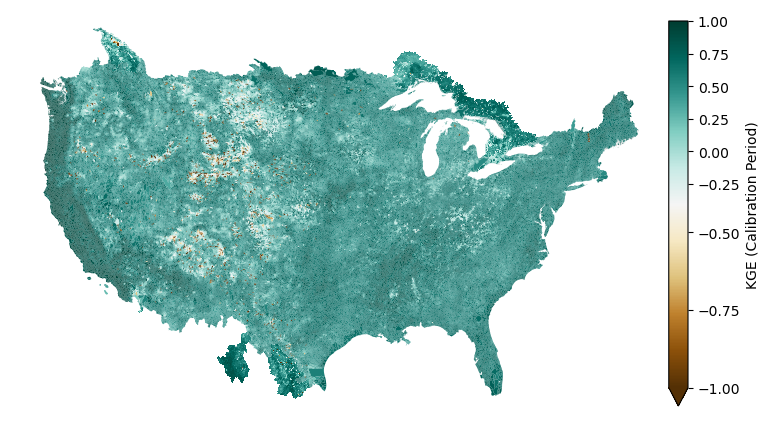

In [27]:
# map
gdf_map = all_reg_shp.merge(kge_decomp_merge,on=['basin'])
plt_norm = mcolors.TwoSlopeNorm(vmin=-1,vmax=1,vcenter=-0.41)

fig,ax = plt.subplots(1,1,figsize=(10,10))
gdf_map.plot(ax=ax,column='kge_calib',norm=plt_norm,
             vmin=-1,vmax=1,cmap='BrBG',
             legend=True,legend_kwds={'label':'KGE (Calibration Period)','extend':'min','shrink':0.5,'pad':0})
ax.set_axis_off()
#plt.savefig(save_fig_path+'figure2_map.pdf',bbox_inches='tight',dpi=400);
plt.savefig(save_fig_path+'figure2_map.png',bbox_inches='tight',dpi=400);

In [ ]:
# mean/variance annual values for calibration target, ERA5-D, ACE2 --> HUC-2? 
annual_df = monthly_df.copy()
annual_df['time'] = pd.to_datetime(annual_df['time'])
annual_df['year'] = annual_df['time'].dt.year
annual_df = annual_df.groupby(['region2_wpfaf','basin','scenario','year'])[['calib_qf','vic_qf']].sum().reset_index() #get annual runoff for each basin in each year

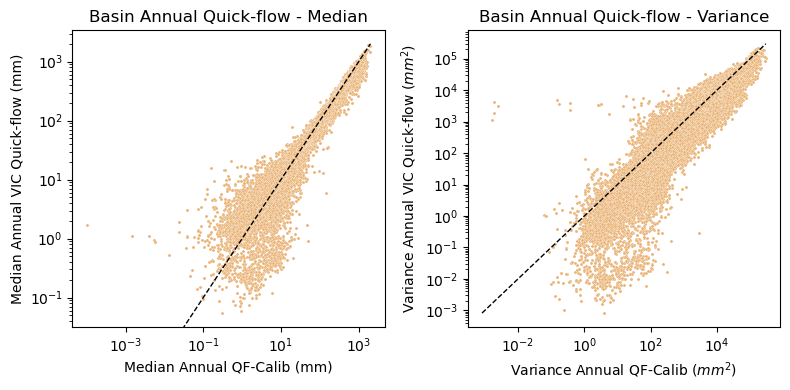

In [ ]:
annual_df_mean = annual_df.groupby(['region2_wpfaf','basin','scenario'])[['calib_qf','vic_qf']].mean().reset_index() #mean annual runoff for each basin
annual_df_median = annual_df.groupby(['region2_wpfaf','basin','scenario'])[['calib_qf','vic_qf']].median().reset_index() #median annual runoff for each basin
annual_df_var = annual_df.groupby(['region2_wpfaf','basin','scenario'])[['calib_qf','vic_qf']].var().reset_index() #variance annual runoff for each basin

annual_df_stats = annual_df_mean.merge(annual_df_median,on=['region2_wpfaf','basin','scenario'],suffixes=['_mean','_median'])
annual_df_stats = annual_df_stats.merge(annual_df_var,on=['region2_wpfaf','basin','scenario'])
annual_df_stats = annual_df_stats.rename(columns={'calib_qf':'calib_qf_var','vic_qf':'vic_qf_var'})

fig,axes = plt.subplots(1,2,figsize=(8,4))
axes = axes.flatten()

ax = axes[0]
sns.scatterplot(ax=ax,data=annual_df_stats[annual_df_stats.scenario=='era5d'],x='calib_qf_median',y='vic_qf_median',color=era5d_color2,s=5,zorder=1,label='ERA5D')
#sns.scatterplot(ax=ax,data=annual_df_stats[annual_df_stats.scenario!='era5d'],x='calib_qf_median',y='vic_qf_median',color=ace2_color2,s=5,zorder=0,label='ACE2')
#1:1 line
minval = np.min([annual_df_stats[annual_df_stats.scenario=='era5d'].calib_qf_median.min(),annual_df_stats[annual_df_stats.scenario=='era5d'].vic_qf_median.min()])
maxval = np.max([annual_df_stats[annual_df_stats.scenario=='era5d'].calib_qf_median.max(),annual_df_stats[annual_df_stats.scenario=='era5d'].vic_qf_median.max()])
sns.lineplot(ax=ax,x=np.linspace(minval,maxval,100),y=np.linspace(minval,maxval,100),color='k',ls='--',lw=1,zorder=2);
ax.set_xlabel('Median Annual QF-Calib (mm)'); ax.set_ylabel('Median Annual VIC Quick-flow (mm)'); 
ax.set_xscale('log'); ax.set_yscale('log');
ax.set_title('Basin Annual Quick-flow - Median');
h,l = ax.get_legend_handles_labels();
ax.legend().set_visible(False)

ax = axes[1]
sns.scatterplot(ax=ax,data=annual_df_stats[annual_df_stats.scenario=='era5d'],x='calib_qf_var',y='vic_qf_var',color=era5d_color2,s=5,zorder=1,label='ERA5D')
#sns.scatterplot(ax=ax,data=annual_df_stats[annual_df_stats.scenario!='era5d'],x='calib_qf_var',y='vic_qf_var',color=ace2_color2,s=5,zorder=0,label='ACE2')
#1:1 line
minval = np.min([annual_df_stats[annual_df_stats.scenario=='era5d'].calib_qf_var.min(),annual_df_stats[annual_df_stats.scenario=='era5d'].vic_qf_var.min()])
maxval = np.max([annual_df_stats[annual_df_stats.scenario=='era5d'].calib_qf_var.max(),annual_df_stats[annual_df_stats.scenario=='era5d'].vic_qf_var.max()])
sns.lineplot(ax=ax,x=np.linspace(minval,maxval,100),y=np.linspace(minval,maxval,100),color='k',ls='--',lw=1,zorder=2);
ax.set_xlabel('Variance Annual QF-Calib ($mm^2$)'); ax.set_ylabel('Variance Annual VIC Quick-flow ($mm^2$)'); 
ax.set_xscale('log'); ax.set_yscale('log');
ax.set_title('Basin Annual Quick-flow - Variance');
ax.legend().set_visible(False)

#fig.legend(h,l,loc='lower center',bbox_to_anchor=(0.5,-0.05),ncol=2)

plt.tight_layout()
#plt.savefig(save_fig_path+'figure2_scatterplots.pdf',bbox_inches='tight',dpi=400);
plt.savefig(save_fig_path+'figure2_scatterplots.png',bbox_inches='tight',dpi=400);


In [ ]:
#correlations
df_stats = annual_df_stats[annual_df_stats.scenario=='era5d']
print(np.corrcoef(df_stats.calib_qf_median,df_stats.vic_qf_median)[0,1])
print(np.corrcoef(df_stats.calib_qf_var,df_stats.vic_qf_var)[0,1])
df_stats = annual_df_stats[annual_df_stats.scenario!='era5d']
print(np.corrcoef(df_stats.calib_qf_median,df_stats.vic_qf_median)[0,1])
print(np.corrcoef(df_stats.calib_qf_var,df_stats.vic_qf_var)[0,1])

0.9724264725702098
0.8664708870710425
0.9501556844523943
0.7353512380989965


### Figure 3: Runoff Volume

In [ ]:
#total runoff volume across ALL basins --> first calculate volume (qf * basin area), sum across basins, divde by total basin area
total_df_cs = monthly_df.copy()
total_df_cs['vic_qf_area'] = total_df_cs['vic_qf']*total_df_cs['basin_area']
total_df_cs['calib_qf_area'] = total_df_cs['calib_qf']*total_df_cs['basin_area']

total_df_cs = total_df_cs.groupby(['time','scenario'])[['vic_qf_area','calib_qf_area']].sum().reset_index() #sum across ALL regions + basins
total_df_cs['vic_qf_cs'] = total_df_cs.groupby(['scenario'])['vic_qf_area'].cumsum()
total_df_cs['calib_qf_cs'] = total_df_cs.groupby(['scenario'])['calib_qf_area'].cumsum()
total_df_cs['time'] = pd.to_datetime(total_df_cs['time'])
total_df_cs['year'] = total_df_cs.time.dt.year
total_df_cs['month'] = total_df_cs.time.dt.month

#divide by area
total_df_cs[['vic_qf_cs','calib_qf_cs']] = total_df_cs[['vic_qf_cs','calib_qf_cs']]/total_area

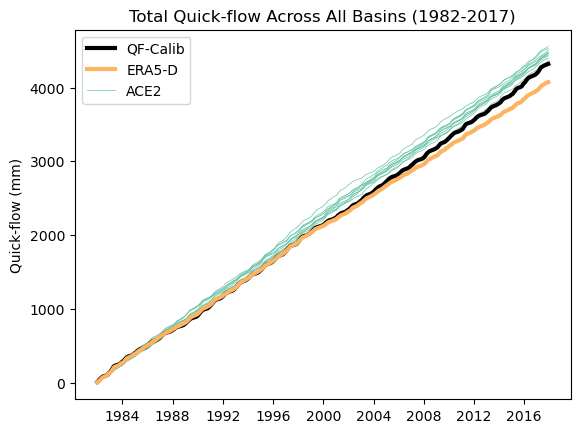

In [ ]:
total_cs_ace2_range = total_df_cs[total_df_cs.scenario!='era5d']
timevals = total_cs_ace2_range.time.unique()
minace2 = total_cs_ace2_range.groupby(['time'])['vic_qf_cs'].min()
maxace2 = total_cs_ace2_range.groupby(['time'])['vic_qf_cs'].max()

fig,ax = plt.subplots(1,1)
sns.lineplot(ax=ax,data=total_df_cs[total_df_cs.scenario=='era5d'],x='time',y='calib_qf_cs',units='scenario',estimator=None,label='QF-Calib',color='k',lw=3,zorder=1)
sns.lineplot(ax=ax,data=total_df_cs[total_df_cs.scenario=='era5d'],x='time',y='vic_qf_cs',units='scenario',estimator=None,label='ERA5-D',color=era5d_color,lw=3,zorder=1)
sns.lineplot(ax=ax,data=total_df_cs[total_df_cs.scenario!='era5d'],x='time',y='vic_qf_cs',units='scenario',estimator=None,label='ACE2',color='#66c2a5',lw=0.5,zorder=0)
#ax.fill_between(timevals,minace2,maxace2,color=ace2_color,label='ACE2',alpha=0.5,zorder=2,lw=1)
h,l = ax.get_legend_handles_labels()
ax.legend().set_visible(False)
ax.legend(h[:3],l[:3],loc='upper left');
ax.set_xlabel(''); ax.set_ylabel('Quick-flow (mm)'); ax.set_title('Total Quick-flow Across All Basins (1982-2017)');
plt.savefig(save_fig_path+'figure3_totalrunoff.pdf',bbox_inches='tight',dpi=400);

In [51]:
#percent difference in december 2017
total_df_cs_dec17 = total_df_cs[total_df_cs.time=='2017-12-01']

In [ ]:
#percent different from calibration target
maxval = total_df_cs_dec17['vic_qf_cs'].max()
minval = total_df_cs_dec17['vic_qf_cs'].min()
calib_val = total_df_cs_dec17['calib_qf_cs'].iloc[0]
print(100*np.abs(maxval-minval)/minval)
print(100*np.abs(maxval-calib_val)/calib_val)


11.869773525355782
5.4702340423953535


In [ ]:
#calculate total runoff volume by month
#calculate cumulative runoff volume
monthly_df_cs = monthly_df.copy()
monthly_df_cs['time'] = pd.to_datetime(monthly_df_cs['time'])
monthly_df_cs['year'] = monthly_df_cs.time.dt.year
monthly_df_cs['month'] = monthly_df_cs.time.dt.month
monthly_df_cs['vic_qf_area'] = monthly_df_cs['vic_qf']*monthly_df_cs['basin_area']
monthly_df_cs['calib_qf_area'] = monthly_df_cs['calib_qf']*monthly_df_cs['basin_area']

monthly_df_cs['vic_qf_cs'] = monthly_df_cs.groupby(['basin','scenario','year'])['vic_qf_area'].cumsum()
monthly_df_cs['calib_qf_cs'] = monthly_df_cs.groupby(['basin','scenario','year'])['calib_qf_area'].cumsum()

# Annual runoff by huc2 region
annual_df_cs = monthly_df_cs[(monthly_df_cs.month==12)].groupby(['region2_wpfaf','scenario','year'])[['vic_qf_cs','calib_qf_cs']].sum().reset_index()
annual_df_cs = annual_df_cs.merge(region2_wpfaf_area,on=['region2_wpfaf'])
annual_df_cs['vic_qf_cs'] = annual_df_cs['vic_qf_cs']/annual_df_cs['basin_area']
annual_df_cs['calib_qf_cs'] = annual_df_cs['calib_qf_cs']/annual_df_cs['basin_area']


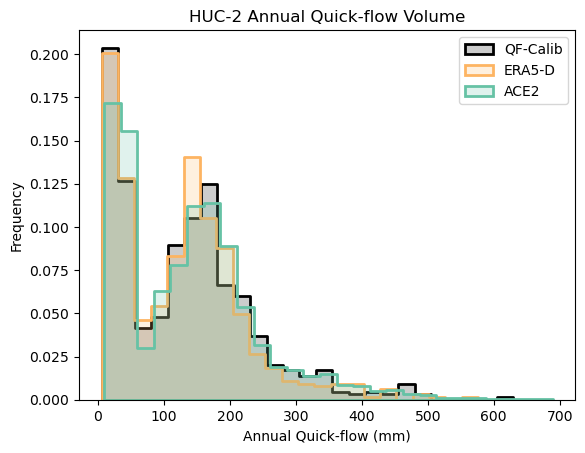

In [ ]:
fig,ax = plt.subplots(1,1)
b = 25
sns.histplot(ax=ax,data=annual_df_cs[annual_df_cs.scenario=='era5d'].calib_qf_cs,stat='probability',element='step',binwidth=b,fill='k',color='k',lw=2,alpha=0.2,label='QF-Calib')
sns.histplot(ax=ax,data=annual_df_cs[annual_df_cs.scenario=='era5d'].vic_qf_cs,stat='probability',element='step',binwidth=b,fill='gray',color=era5d_color,lw=2,alpha=0.2,label='ERA5-D')
sns.histplot(ax=ax,data=annual_df_cs[annual_df_cs.scenario!='era5d'].vic_qf_cs,stat='probability',element='step',binwidth=b,fill='#8dd3c7',color=ace2_color,lw=2,alpha=0.2,label='ACE2')
ax.set_xlabel('Annual Quick-flow (mm)'); ax.set_title('HUC-2 Annual Quick-flow Volume'); ax.set_ylabel('Frequency');
ax.legend()
plt.savefig(save_fig_path+'figure3_histogram.pdf',bbox_inches='tight',dpi=400);

### Figure 4: Seasonality

In [ ]:
#calculate monthly runoff across each HUC2 region
monthly_huc2_df = monthly_df.copy()
monthly_huc2_df['year'] = monthly_huc2_df['time'].dt.year
monthly_huc2_df['month'] = monthly_huc2_df['time'].dt.month
monthly_huc2_df['vic_qf_area'] = monthly_huc2_df['vic_qf']*monthly_huc2_df['basin_area']
monthly_huc2_df['calib_qf_area'] = monthly_huc2_df['calib_qf']*monthly_huc2_df['basin_area']

#sum across huc-2 region
monthly_huc2_df = monthly_huc2_df.groupby(['region2_wpfaf','scenario','time','year','month'])[['calib_qf_area','vic_qf_area']].sum().reset_index()
monthly_huc2_df = monthly_huc2_df.merge(region2_wpfaf_area,on=['region2_wpfaf'])

#divide by area
monthly_huc2_df['calib_qf'] = monthly_huc2_df['calib_qf_area']/monthly_huc2_df['basin_area']
monthly_huc2_df['vic_qf'] = monthly_huc2_df['vic_qf_area']/monthly_huc2_df['basin_area']

In [75]:
#for ace2, calculate mean for each scenario
monthly_huc2_df_ace2_mean = monthly_huc2_df.groupby(['region2_wpfaf','scenario','month'])['vic_qf'].mean().reset_index()
monthly_huc2_df_ace2_2p5 = monthly_huc2_df.groupby(['region2_wpfaf','scenario','month'])['vic_qf'].quantile(0.025).reset_index()
monthly_huc2_df_ace2_97p5 = monthly_huc2_df.groupby(['region2_wpfaf','scenario','month'])['vic_qf'].quantile(0.975).reset_index()
#merge
monthly_huc2_df_ace2 = monthly_huc2_df_ace2_mean.merge(monthly_huc2_df_ace2_2p5,on=['region2_wpfaf','scenario','month'],suffixes=['_mean','_q2p5'])
monthly_huc2_df_ace2 = monthly_huc2_df_ace2.merge(monthly_huc2_df_ace2_97p5,on=['region2_wpfaf','scenario','month'])
monthly_huc2_df_ace2 = monthly_huc2_df_ace2.rename(columns={'vic_qf':'vic_qf_q97p5'})

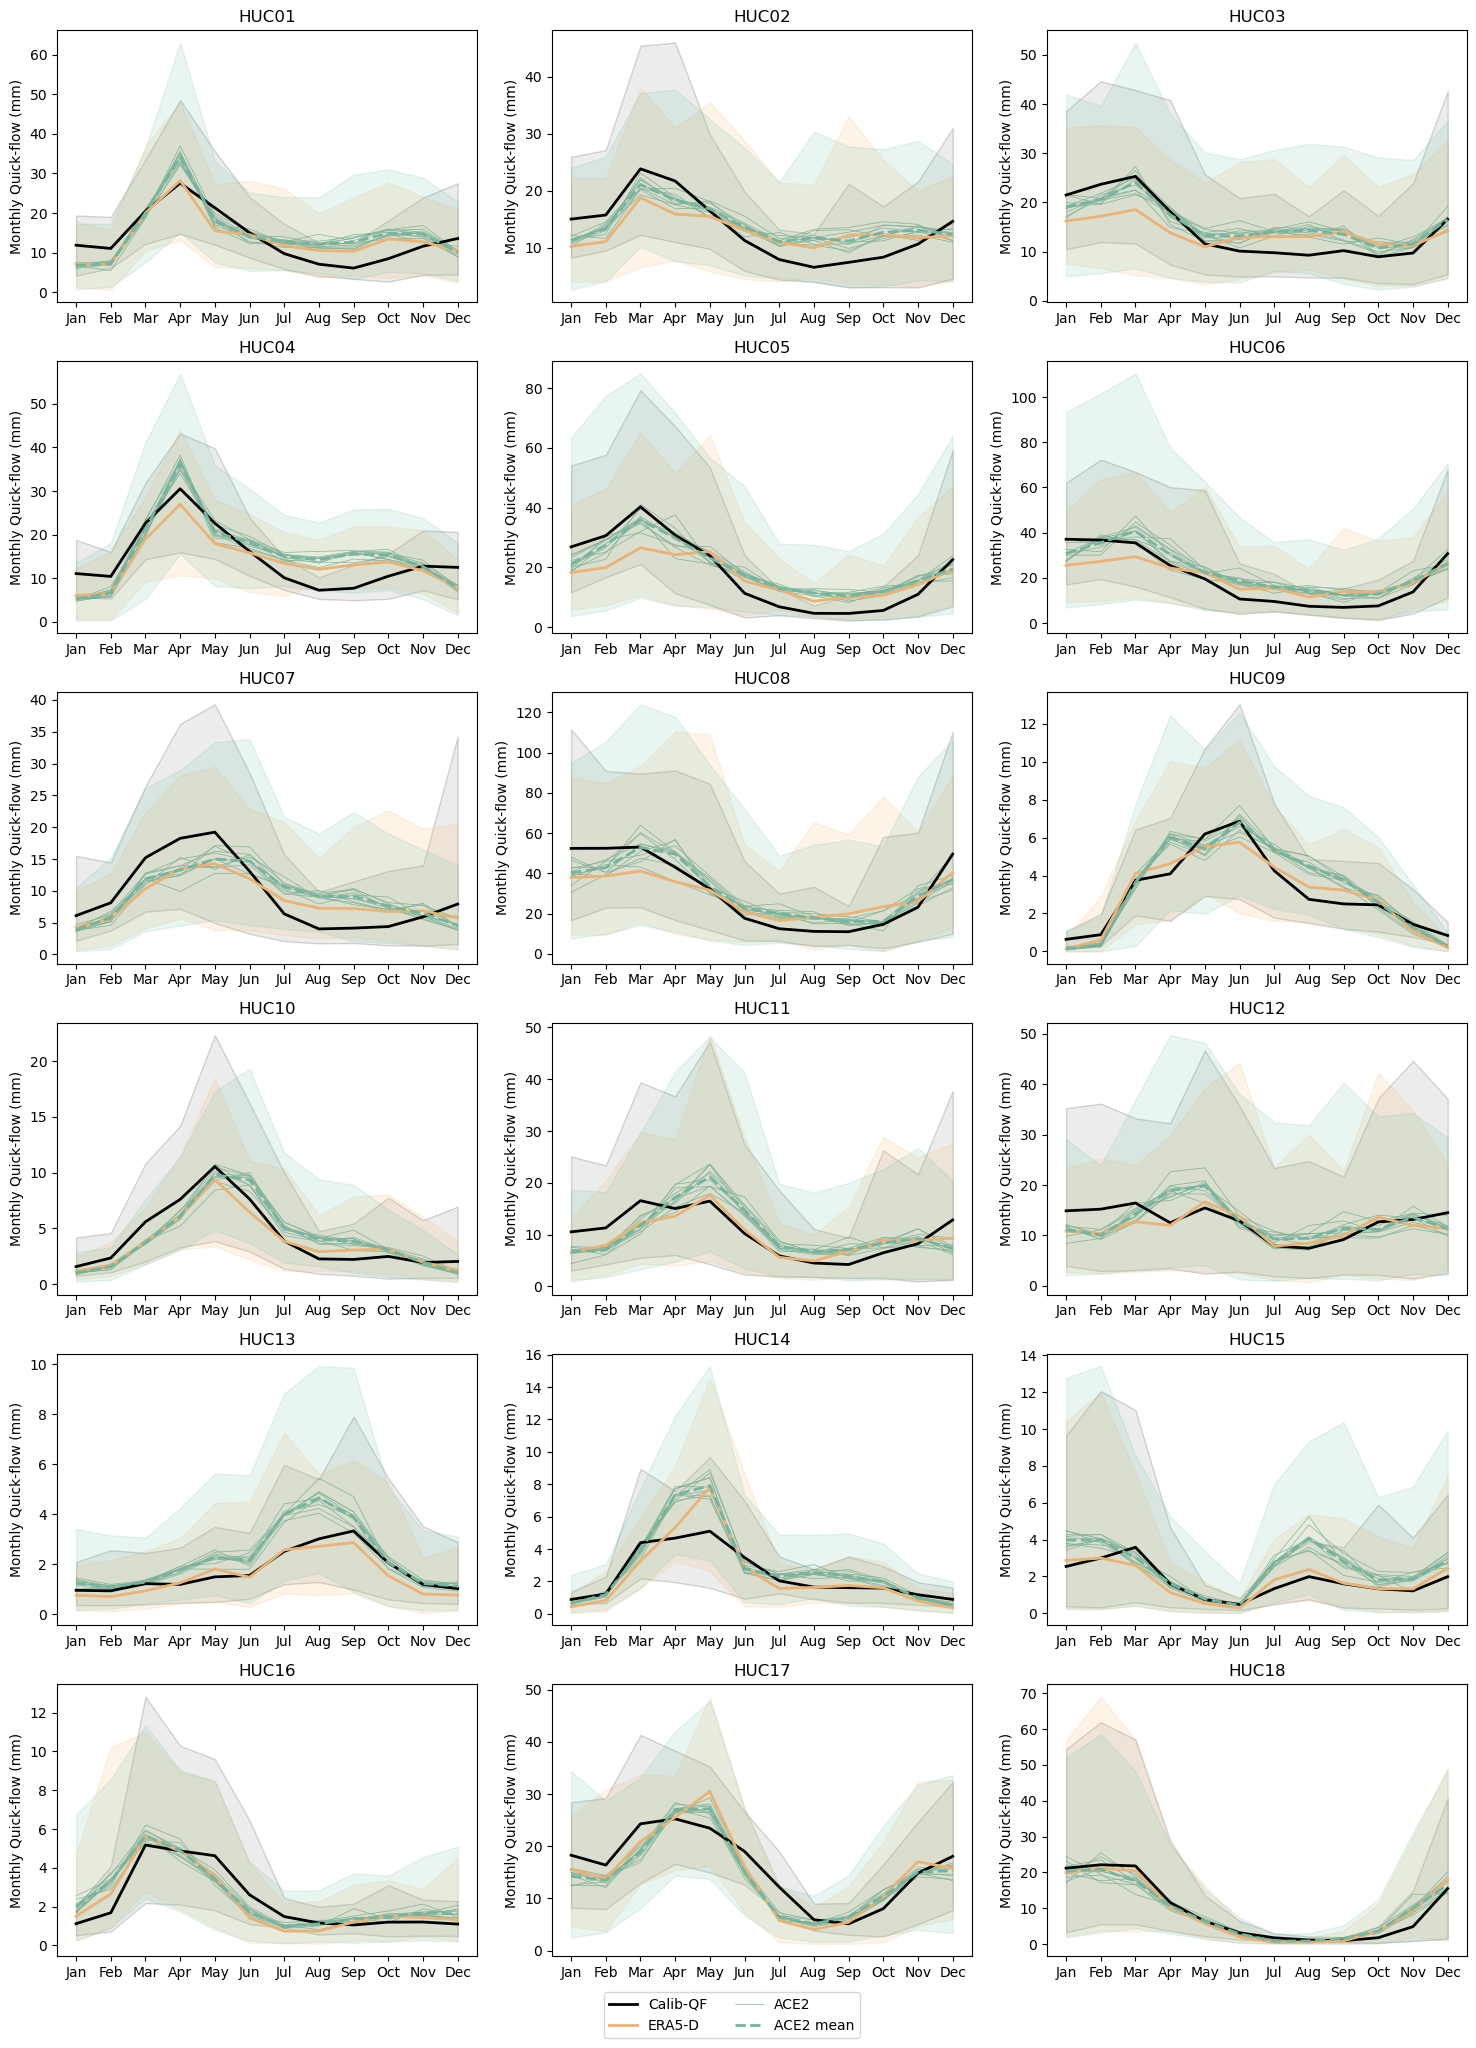

In [ ]:
month_list = [1,2,3,4,5,6,7,8,9,10,11,12]
month_labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

fig,axes = plt.subplots(6,3,figsize=(15,20))
axes = axes.flatten()

reg_list = [ 'huc01',  'huc02',  'huc03',  'huc04',  'huc05',  'huc06',  'huc07',
  'huc08',  'huc09',  'huc10',  'huc11',  'huc12',  'huc13',  'huc14',
  'huc15',  'huc16',  'huc17',  'huc18']

for i in range(len(reg_list)):
    ax = axes[i]
    reg_sel = reg_list[i]




    sns.lineplot(ax=ax,data=monthly_huc2_df[monthly_huc2_df.region2_wpfaf==reg_sel].drop_duplicates('calib_qf'),
                                    x='month',y='calib_qf',estimator='mean',color='k',label='Calib-QF',lw=2,
                                    errorbar=('pi',95),err_kws = {'alpha':0.15,'facecolor':'gray'})

    sns.lineplot(ax=ax,data=monthly_huc2_df[(monthly_huc2_df.region2_wpfaf==reg_sel) & (monthly_huc2_df.scenario=='era5d')],
                                    x='month',y='vic_qf',estimator='mean',color=era5d_color2,label='ERA5-D',lw=2,
                                    errorbar=('pi',95),err_kws = {'alpha':0.15,'facecolor':era5d_color})

    sns.lineplot(ax=ax,data=monthly_huc2_df_ace2[(monthly_huc2_df_ace2.region2_wpfaf==reg_sel) & (monthly_huc2_df_ace2.scenario!='era5d')],
                                    x='month',y='vic_qf_mean',estimator=None,units='scenario',lw=0.5,color=ace2_color2,zorder=0,label='ACE2')
    
    sns.lineplot(ax=ax,data=monthly_huc2_df[(monthly_huc2_df.region2_wpfaf==reg_sel) & (monthly_huc2_df.scenario!='era5d')],
                                    x='month',y='vic_qf',estimator='mean',color=ace2_color2,label='ACE2 mean',lw=2,ls='--',
                                    errorbar=('pi',95),err_kws = {'alpha':0.15,'facecolor':ace2_color})


    ax.set_title(reg_sel.upper()); ax.set_xlabel(''); ax.set_ylabel('Monthly Quick-flow (mm)');   

    ax.set_xticks([1,2,3,4,5,6,7,8,9,10,11,12]); ax.set_xticklabels(month_labels);

    if i == 0:
        h,l = ax.get_legend_handles_labels()
    ax.legend().set_visible(False)

h = h[:3]+[h[-1]]
l = l[:3]+[l[-1]]
plt.tight_layout()
fig.legend(h,l,loc='lower center',bbox_to_anchor=(0.5,-0.025),ncol=2)
plt.savefig(save_fig_path+'figure4_seasonality.pdf',bbox_inches='tight',dpi=400);

In [87]:
l

[['Calib-QF', 'ERA5-D', 'ACE2'], 'ACE2 Mean']

### Figure 5: Daily Quantiles

In [37]:
dqp = '/gcfs/projects/foresight/hydrology/abirn_vic/vic_output_analysis/saved_data/daily_quantiles/'

reg_list = ['huc01','huc02','huc03','huc04','huc05','huc06','huc07','huc08','huc09','huc09','huc10','huc11',
            'huc12','huc13','huc14','huc15','huc16','huc17','huc18','pfaf71','pfaf72','pfaf73','pfaf75',
            'pfaf77','pfaf78']
df_low = []
df_high = []
for reg_sel in reg_list:
    df_low.append(pd.read_csv(dqp+reg_sel+'_7q10min.csv',dtype={'basin':'str','region2':'str'}))
    df_high.append(pd.read_csv(dqp+reg_sel+'_5q10max.csv',dtype={'basin':'str','region2':'str'}))
df_low = pd.concat(df_low, ignore_index=True)
df_high = pd.concat(df_high,ignore_index=True)

df_quantiles = df_low.merge(df_high,on=['region2','basin','scenario'],suffixes=['_low','_high'])
df_quantiles = df_quantiles.rename(columns={'vic_qf_bf_10_low':'vic_7q10','vic_qf_bf_10_high':'vic_am'})
df_quantiles.loc[df_quantiles.scenario.str.contains('era5d'),'scenario_type'] = 'ERA5D'
df_quantiles.loc[df_quantiles.scenario.str.contains('fhist'),'scenario_type'] = 'ACE2'

#link pfaf basins with huc2regions
huc2_pfaf_link = pd.read_csv('extra_data/pfaf_huc2_link.csv',dtype={'pfaf_id':'str','region2':'str'})
huc2_pfaf_link['region2'] = 'pfaf'+huc2_pfaf_link['region2']

#merge pfaf links with monthly_df --> assign new column region2_wpfaf
df_quantiles = df_quantiles.merge(huc2_pfaf_link,left_on=['basin','region2'],right_on=['pfaf_id','region2'],how='outer')
df_quantiles.loc[df_quantiles.region2.str.contains('huc'),'region2_wpfaf'] = df_quantiles.region2
df_quantiles.loc[df_quantiles.region2.str.contains('pfaf'),'region2_wpfaf'] = df_quantiles.asc_huc2

save_path = '/gcfs/projects/foresight/hydrology/abirn_vic/vic_output_analysis/saved_data/'
df_quantiles.to_csv(save_path+'daily_quantiles.csv',index=False)

#

In [38]:
dq_path = '/gcfs/projects/foresight/hydrology/abirn_vic/vic_output_analysis/saved_data/'
df_quantiles = pd.read_csv(dq_path+'daily_quantiles.csv',dtype={'basin':str})
df_quantiles['region2_wpfaf_upper'] = df_quantiles['region2_wpfaf'].str.upper()
df_quantiles_mean = df_quantiles.groupby(['region2_wpfaf','region2_wpfaf_upper','basin','scenario_type'])[['vic_7q10min','vic_5q10max']].mean().reset_index()

/tmp/ipykernel_569612/496166349.py:2: DtypeWarning: Columns (0: asc_huc2) have mixed types. Specify dtype option on import or set low_memory=False.
  df_quantiles = pd.read_csv(dq_path+'daily_quantiles.csv',dtype={'basin':str})


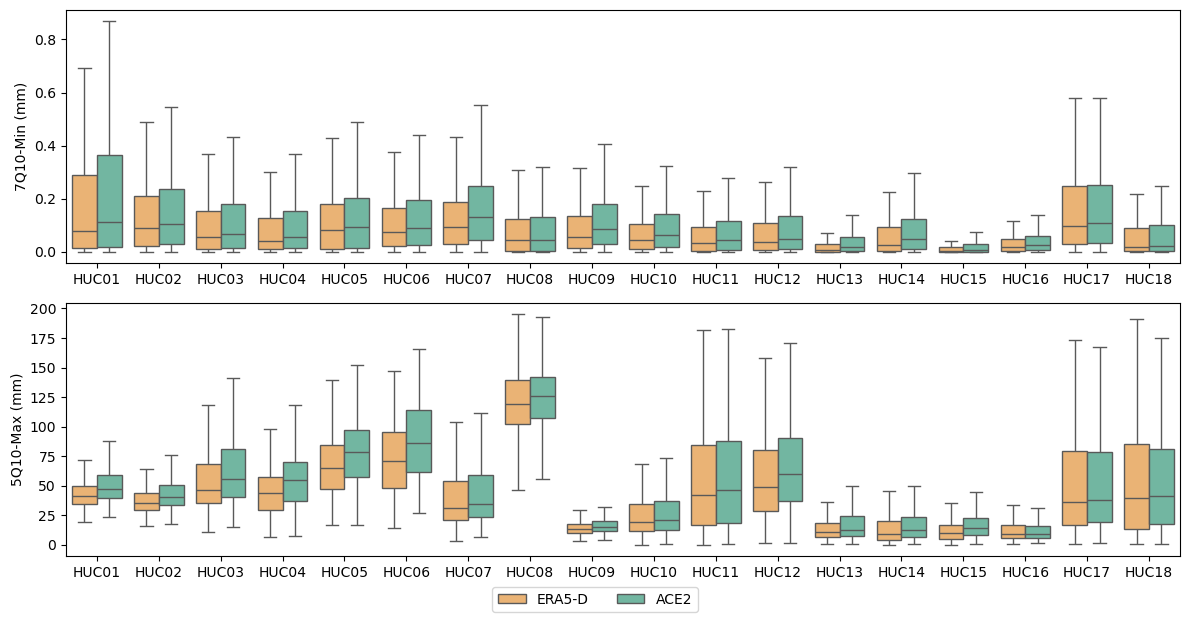

In [39]:
fig,axes = plt.subplots(2,1,figsize=(12,6))
axes = axes.flatten()

ax = axes[0]
sns.boxplot(ax=ax,data=df_quantiles_mean,x='region2_wpfaf_upper',y='vic_7q10min',hue='scenario_type',showfliers=False,palette=[era5d_color,ace2_color],hue_order = ['ERA5D','ACE2'])
ax.set_ylabel('7Q10-Min (mm)'); 
ax.set_xlabel('');
h,l = ax.get_legend_handles_labels()
ax.legend(title='');ax.legend().set_visible(False)

ax = axes[1]
sns.boxplot(ax=ax,data=df_quantiles_mean,x='region2_wpfaf_upper',y='vic_5q10max',hue='scenario_type',showfliers=False,palette=[era5d_color,ace2_color],hue_order = ['ERA5D','ACE2'])
#ax.set_yscale('log'); 
ax.set_ylabel('5Q10-Max (mm)');
ax.set_xlabel('');
ax.legend(title=''); ax.legend().set_visible(False)

l = ['ERA5-D','ACE2']
fig.legend(h[:2],l[:2],loc='lower center',bbox_to_anchor=(0.5,-0.04),ncol=2)
plt.tight_layout()
#plt.savefig(save_fig_path+'figure5_boxplots.pdf',bbox_inches='tight',dpi=400);
plt.savefig(save_fig_path+'figure5_boxplots.png',bbox_inches='tight',dpi=400);

In [40]:
df_quantiles_mean_split = df_quantiles_mean[df_quantiles_mean.scenario_type=='ERA5D'].merge(df_quantiles_mean[df_quantiles_mean.scenario_type=='ACE2'],
on=['region2_wpfaf_upper','basin'],suffixes=['_era5d','_ace2'])

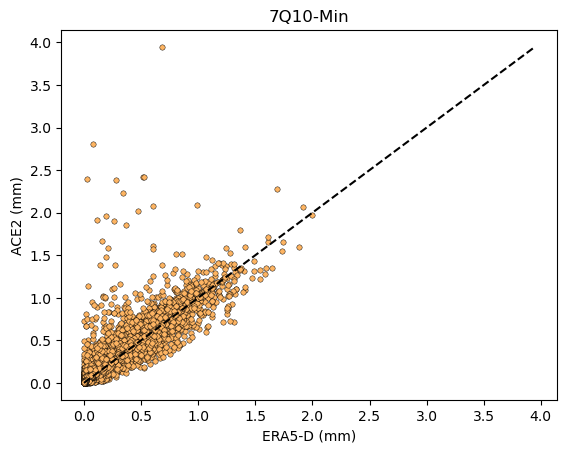

In [41]:
fig,ax = plt.subplots(1,1)
sns.scatterplot(ax=ax,data=df_quantiles_mean_split,x='vic_7q10min_era5d',y='vic_7q10min_ace2',color=era5d_color,edgecolor='k',s=15)
minval = np.min([df_quantiles_mean_split.vic_7q10min_era5d.min(),df_quantiles_mean_split.vic_7q10min_ace2.min()])
maxval = np.max([df_quantiles_mean_split.vic_7q10min_era5d.max(),df_quantiles_mean_split.vic_7q10min_ace2.max()])
sns.lineplot(ax=ax,x=np.linspace(minval,maxval,100),y=np.linspace(minval,maxval,100),color='k',ls='--')
ax.set_xlabel('ERA5-D (mm)'); ax.set_ylabel('ACE2 (mm)'); ax.set_title('7Q10-Min')
#plt.savefig(save_fig_path+'figure5_7q10min.pdf',bbox_inches='tight',dpi=400);
plt.savefig(save_fig_path+'figure5_7q10min.png',bbox_inches='tight',dpi=400);

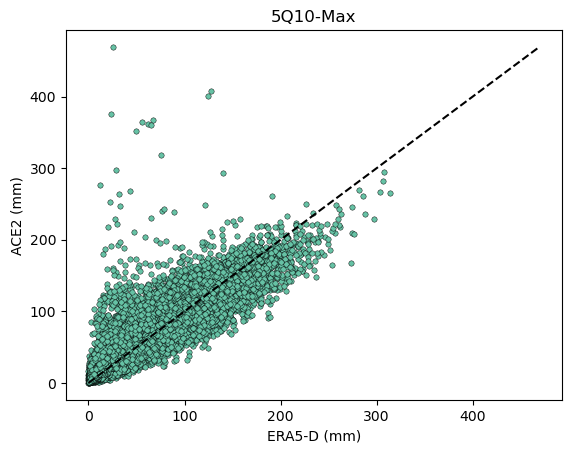

In [42]:
fig,ax = plt.subplots(1,1)
sns.scatterplot(ax=ax,data=df_quantiles_mean_split,x='vic_5q10max_era5d',y='vic_5q10max_ace2',color=ace2_color,edgecolor='k',s=15)
minval = np.min([df_quantiles_mean_split.vic_5q10max_era5d.min(),df_quantiles_mean_split.vic_5q10max_ace2.min()])
maxval = np.max([df_quantiles_mean_split.vic_5q10max_era5d.max(),df_quantiles_mean_split.vic_5q10max_ace2.max()])
sns.lineplot(ax=ax,x=np.linspace(minval,maxval,100),y=np.linspace(minval,maxval,100),color='k',ls='--')
ax.set_xlabel('ERA5-D (mm)'); ax.set_ylabel('ACE2 (mm)'); ax.set_title('5Q10-Max')
#plt.savefig(save_fig_path+'figure5_5q10max.pdf',bbox_inches='tight',dpi=400);
plt.savefig(save_fig_path+'figure5_5q10max.png',bbox_inches='tight',dpi=400);